In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import os

path = kagglehub.dataset_download("deeplumiere/accident-analysis-dataset")
csv_path = os.path.join(path, "accident_data.csv")
df = pd.read_csv(csv_path)

print("--- 1. FIRST 5 ROWS (df.head()) ---")
print(df.head())

print("\n--- 2. DATASET INFO (df.info()) ---")
df.info()

print("\n--- 3. STATISTICAL SUMMARY (df.describe()) ---")
print(df.describe())

print("\n--- 4. MISSING VALUES (df.isnull().sum()) ---")
print(df.isnull().sum())

d:\REVATURE TRAINING\BadrAl-Dhaibani\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- 1. FIRST 5 ROWS (df.head()) ---
           Index Accident_Severity Accident Date   Latitude  \
0  200701BS64157           Serious    05-06-2019  51.506187   
1  200701BS65737           Serious    02-07-2019  51.495029   
2  200701BS66127           Serious    26-08-2019  51.517715   
3  200701BS66128           Serious    16-08-2019  51.495478   
4  200701BS66837            Slight    03-09-2019  51.488576   

              Light_Conditions           District Area  Longitude  \
0        Darkness - lights lit  Kensington and Chelsea  -0.209082   
1                     Daylight  Kensington and Chelsea  -0.173647   
2  Darkness - lighting unknown  Kensington and Chelsea  -0.210215   
3                     Daylight  Kensington and Chelsea  -0.202731   
4        Darkness - lights lit  Kensington and Chelsea  -0.192487   

   Number_of_Casualties  Number_of_Vehicles Road_Surface_Conditions  \
0                     1                   2                     Dry   
1                     1     

In [3]:
# Data Cleaning & Preprocessing Steps
# 1. Drop rows where critical target or location is missing
df = df.dropna(subset=['Accident_Severity', 'Latitude', 'Longitude'])

# 2. Impute categorical missing values with 'Unknown'
df['Road_Surface_Conditions'].fillna('Unknown', inplace=True)
df['Road_Type'].fillna('Unknown', inplace=True)
df['Weather_Conditions'].fillna('Unknown', inplace=True)
df['Urban_or_Rural_Area'].fillna('Unknown', inplace=True)

# 3. Convert 'Accident Date' (with space) to datetime
df['Accident_Date'] = pd.to_datetime(df['Accident Date'], format='%d-%m-%Y', errors='coerce')
df['Year'] = df['Accident_Date'].dt.year
df['Month'] = df['Accident_Date'].dt.month
df['YearMonth'] = df['Accident_Date'].dt.to_period('M').astype(str)

C:\Users\badrd\AppData\Local\Temp\ipykernel_9660\2617174841.py:6: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Road_Surface_Conditions'].fillna('Unknown', inplace=True)
C:\Users\badrd\AppData\Local\Temp\ipykernel_9660\2617174841.py:7: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through cha

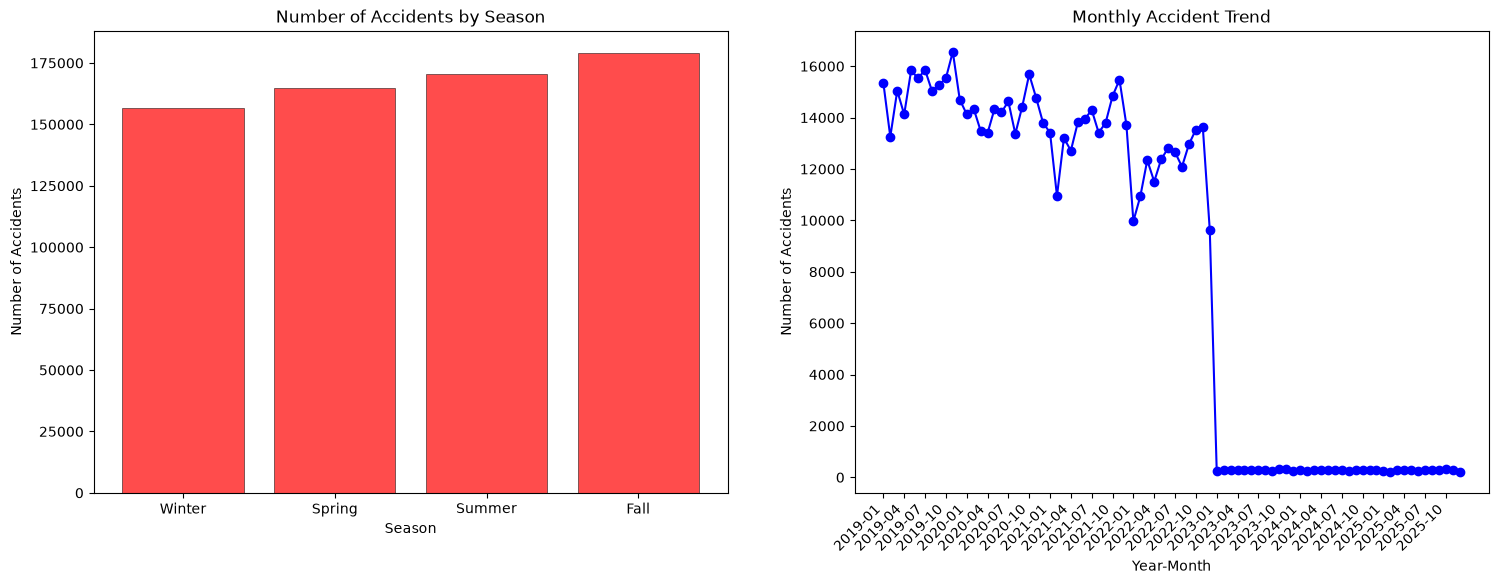

Observations:
Surprisingly the number of accidents is lowest in Winter, which is counterintuitive as one might expect more accidents due to icy conditions.
The drop in acccidents after 2023 is a problem with the dataset being incomplete past that year


In [4]:
# Number of Accidents by Season and by Month
# Map each month to its season
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Fall', 10: 'Fall', 11: 'Fall'}
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
df['Season'] = df['Month'].map(season_map)

season_counts = df['Season'].value_counts().reindex(season_order)  # aggregated across all years
monthly_counts = df.groupby('YearMonth').size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

ax1.set_title('Number of Accidents by Season')
ax1.bar(season_counts.index, season_counts.values,
        color='red',
        edgecolor='black',
        linewidth=0.5,
        alpha=0.7
        )
ax1.set_xlabel('Season')
ax1.set_ylabel('Number of Accidents')

ax2.set_title('Monthly Accident Trend')
ax2.plot(monthly_counts.index, monthly_counts.values, marker='o', color='b')
ax2.set_xlabel('Year-Month')
ax2.set_ylabel('Number of Accidents')
ax2.set_xticks(range(0, len(monthly_counts), 3))  # every 3rd month so labels don't overlap
ax2.set_xticklabels(monthly_counts.index[::3], rotation=45, ha='right')


plt.show()
print("Observations:")
print("Surprisingly the number of accidents is lowest in Winter, which is counterintuitive as one might expect more accidents due to icy conditions.")
print("The drop in acccidents after 2023 is a problem with the dataset being incomplete past that year")

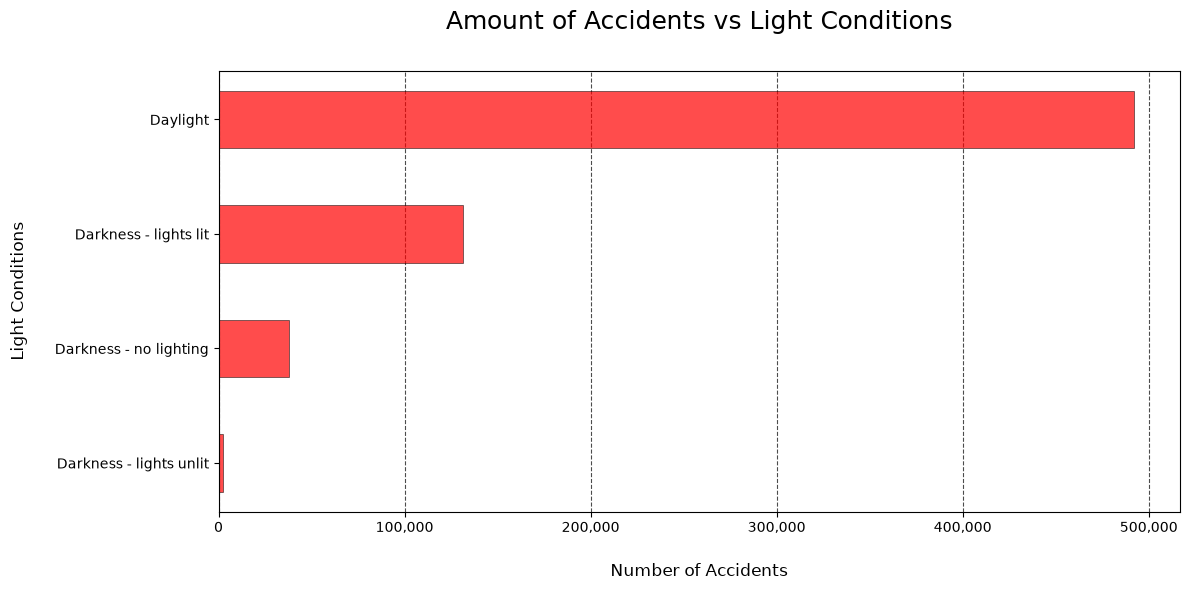

In [16]:
light_conditions_count = df['Light_Conditions'].value_counts(ascending=True)
light_conditions_count = light_conditions_count.drop('Darkness - lighting unknown')

fig, ax = plt.subplots(figsize=(12,6))

ax.set_title('Amount of Accidents vs Light Conditions', fontsize=18, pad=30)

ax.set_xlabel('Number of Accidents', fontsize=12, labelpad=20)
ax.set_ylabel('Light Conditions', fontsize=12, labelpad=20)

ax.barh(light_conditions_count.index, light_conditions_count.values,
        color='red',
        edgecolor='black',
        linewidth=0.5,
        height=0.5,
        alpha=0.7
        )

ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))  # adding commas to big numbers (500000 -> 500,000)


ax.grid(axis='x',
        linestyle='--',
        color='black',
        alpha=0.7)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()


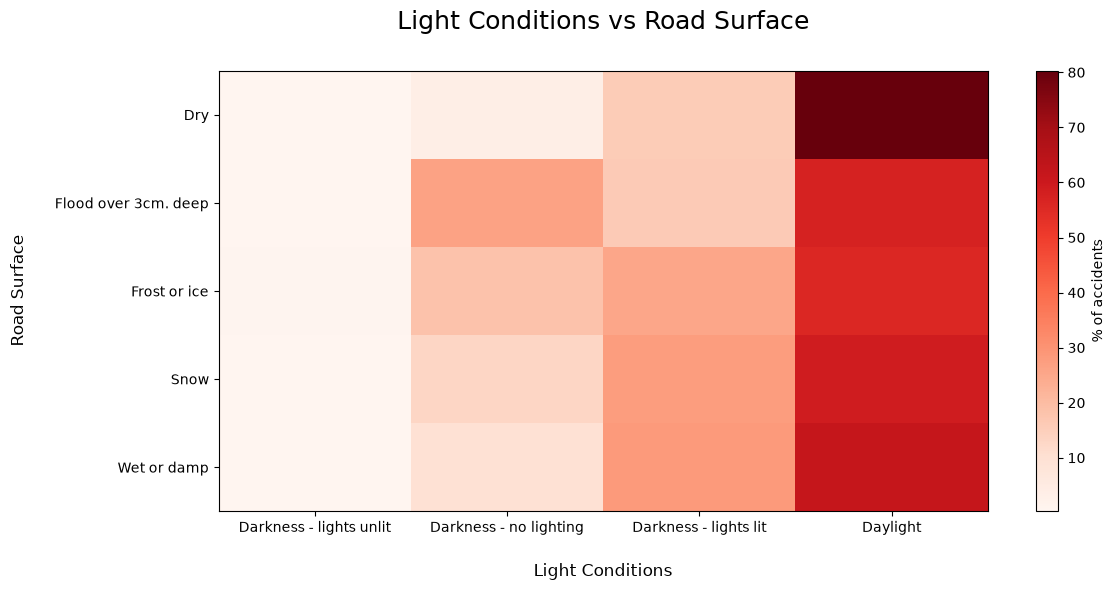

In [ ]:
filtered_df = df[df['Light_Conditions'] != 'Darkness - lighting unknown']
road_surface = filtered_df['Road_Surface_Conditions']
light_conditions = filtered_df['Light_Conditions']
cross_tab = pd.crosstab(road_surface, light_conditions, rownames=['road_surface'], colnames=['light_condition'], normalize='index')
cross_tab *= 100
cross_tab = cross_tab.round(1)
cross_tab = cross_tab[cross_tab.mean().sort_values().index]

fig, ax = plt.subplots(figsize=(12,6))

ax.set_title('Light Conditions vs Road Surface', fontsize=18, pad=30)

im = ax.imshow(cross_tab, aspect='auto', cmap='Reds')  # image show plot
fig.colorbar(im, ax=ax, label='% of accidents')  # color bar for % of accidents

# x and y axis indices and labels
ax.set_xticks(range(len(cross_tab.columns)), labels=cross_tab.columns)
ax.set_yticks(range(len(cross_tab.index)), labels=cross_tab.index)
ax.set_xlabel('Light Conditions', fontsize=12, labelpad=20)
ax.set_ylabel('Road Surface', fontsize=12, labelpad=20)

fig.tight_layout()
plt.show()


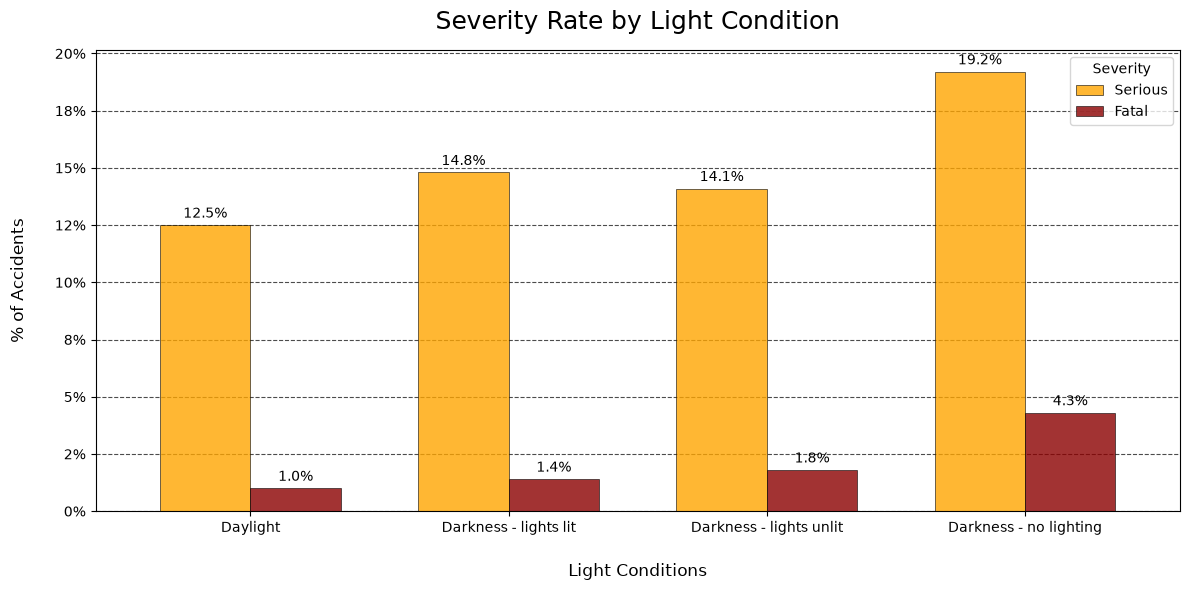

In [ ]:
severity = filtered_df['Accident_Severity']
cross_tab = pd.crosstab(light_conditions, severity, rownames=['light_conditions'], colnames=['severity'], normalize='index')
cross_tab *= 100
cross_tab = cross_tab.round(1)

cross_tab = cross_tab.drop(columns='Slight')
cross_tab = cross_tab[['Serious', 'Fatal']]
cross_tab = cross_tab.sort_values('Fatal')

fig, ax = plt.subplots(figsize=(12,6))

ax.set_title('Severity Rate by Light Condition', fontsize=18, pad=15)

cross_tab.plot(kind='bar', ax=ax,
               color=['orange', 'darkred'],
               edgecolor='black',
               linewidth=0.5,
               alpha=0.8,
               width=0.7)

ax.grid(axis='y',
        linestyle='--',
        color='black',
        alpha=0.7)
ax.set_axisbelow(True)
ax.legend(title='Severity')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)   

ax.set_xlabel('Light Conditions', fontsize=12, labelpad=20)
ax.set_ylabel('% of Accidents', fontsize=12, labelpad=20)

ax.yaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(5))   # ticks at 0, 5, 10, 15, 20
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:.0f}%"))

ax.tick_params(axis='x', rotation=0)

fig.tight_layout()
plt.show()